# Dự đoán rủi ro vỡ nợ tín dụng từ dữ liệu đa nguồn với Apache Spark

**Học phần:** Nhập môn Big Data · **GVHD:** TS. Ngô Dương Hà · **Sinh viên thực hiện:** Nguyễn Hải Đăng .
**Dữ liệu:** Home Credit Default Risk (Kaggle) · **Lưu trữ:** HDFS (hoặc ổ đĩa cục bộ) · **Xử lý:** Apache Spark (Spark SQL, DataFrame, MLlib)

Luồng xử lý trong notebook:

1. Cấu hình, khởi tạo SparkSession, kết nối HDFS
2. Nạp 7 bảng CSV từ HDFS → ghi lại dạng Parquet trên HDFS (so sánh dung lượng, tốc độ đọc)
3. Khảo sát chất lượng dữ liệu: trùng lặp, giá trị thiếu, ngoại lệ
4. Khám phá dữ liệu bằng Spark SQL
5. Làm sạch và tạo đặc trưng trên bảng hồ sơ
6. Tổng hợp đặc trưng từ 6 bảng lịch sử và JOIN theo `SK_ID_CURR`
7. Huấn luyện 3 mô hình Spark MLlib (Logistic Regression làm baseline, Random Forest, GBT)
8. Đánh giá (AUC-ROC, AUC-PR, Precision, Recall, F1), đường ROC, độ quan trọng đặc trưng
9. So sánh thời gian Spark và pandas
10. Demo chấm điểm, lưu mô hình và xuất dữ liệu cho dashboard (`app.py`)

Mọi số liệu và hình dùng trong báo cáo được lưu vào thư mục `results/`.

## 0. Cấu hình

In [1]:
import os, time, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# ===== Chọn nơi lưu trữ =====
# "hdfs" : đọc CSV và ghi Parquet trên HDFS (cần chạy HDFS trước, xem README mục 3)
# "local": dùng thư mục data/ và parquet/ trên máy (khi chưa cài HDFS)
STORAGE  = "hdfs"
HDFS_URI = "hdfs://localhost:9000/credit-risk"

DATA_DIR   = Path("data")          # CSV trên máy (pandas dùng để so sánh; cũng là nguồn để đưa lên HDFS)
RESULT_DIR = Path("results")
FIG_DIR    = RESULT_DIR / "figures"
DASH_DIR   = RESULT_DIR / "dashboard"   # dữ liệu cho dashboard Streamlit
for d in (RESULT_DIR, FIG_DIR, DASH_DIR):
    d.mkdir(parents=True, exist_ok=True)

if STORAGE == "hdfs":
    RAW_ROOT, PARQUET_ROOT = f"{HDFS_URI}/raw", f"{HDFS_URI}/parquet"
else:
    RAW_ROOT, PARQUET_ROOT = str(DATA_DIR.resolve()), str(Path("parquet").resolve())

SAMPLE_FRACTION = 1.0   # đặt 0.2 để chạy thử nhanh với 20% hồ sơ
RUN_TUNING      = False # True: chạy thêm CrossValidator cho GBT (lâu)
SEED            = 42

TABLES = ["application_train", "bureau", "bureau_balance", "previous_application",
          "POS_CASH_balance", "installments_payments", "credit_card_balance"]
raw_path = lambda t: f"{RAW_ROOT}/{t}.csv"
pq_path  = lambda t: f"{PARQUET_ROOT}/{t}"
print("Lưu trữ:", STORAGE, "|", RAW_ROOT)

Lưu trữ: hdfs | hdfs://localhost:9000/credit-risk/raw


In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .appName("HomeCredit-CreditRisk")
         .master("local[*]")                               # dùng toàn bộ nhân CPU
         .config("spark.driver.memory", "8g")              # Mac 16 GB: để 8 GB cho Spark
         .config("spark.sql.shuffle.partitions", "16")     # local mode không cần 200 partition
         .config("spark.sql.adaptive.enabled", "true")     # Adaptive Query Execution
         .config("spark.sql.ansi.enabled", "false")        # chia cho 0 trả về null thay vì lỗi
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

# Truy cập hệ thống tệp (HDFS hoặc cục bộ) qua API Hadoop FileSystem
_jvm, _conf = spark._jvm, spark._jsc.hadoopConfiguration()
def hpath(p): return _jvm.org.apache.hadoop.fs.Path(p)
def hfs(p):   return hpath(p).getFileSystem(_conf)
def exists(p): return hfs(p).exists(hpath(p))
def size_mb(p): return hfs(p).getContentSummary(hpath(p)).getLength() / 1024**2

print("Spark version :", spark.version)
print("Số luồng song song:", spark.sparkContext.defaultParallelism)
print("Spark UI      :", spark.sparkContext.uiWebUrl)   # mở link này khi demo
missing = [t for t in TABLES if not exists(raw_path(t))]
print("Thiếu file:", missing if missing else "không")
if STORAGE == "hdfs":
    print("HDFS Web UI   : http://localhost:9870  (Utilities → Browse the file system → /credit-risk)")

26/11/19 16:04:24 WARN Utils: Your hostname, MacBook-cua-ang.local resolves to a loopback address: 127.0.0.1; using 192.168.1.25 instead (on interface en0)
26/11/19 16:04:24 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 16:04:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version : 3.5.9
Số luồng song song: 10
Spark UI      : http://192.168.1.25:4040
Thiếu file: không
HDFS Web UI   : http://localhost:9870  (Utilities → Browse the file system → /credit-risk)


In [3]:
TIMINGS = {}
class timer:
    """Đo thời gian một khối lệnh và lưu vào TIMINGS."""
    def __init__(self, name): self.name = name
    def __enter__(self):
        self.t = time.perf_counter(); return self
    def __exit__(self, *exc):
        TIMINGS[self.name] = round(time.perf_counter() - self.t, 2)
        print(f"[{self.name}] {TIMINGS[self.name]} giây")

import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR = "#1F4E79"; ACCENT = "#C0504D"

## 1. Nạp dữ liệu CSV và chuyển sang Parquet

In [4]:
raw = {}
with timer("1_doc_csv_infer_schema"):
    for t in TABLES:
        raw[t] = spark.read.csv(raw_path(t), header=True, inferSchema=True)

stats = []
for t, df in raw.items():
    stats.append({"bang": t, "so_dong": df.count(), "so_cot": len(df.columns),
                  "csv_MB": round(size_mb(raw_path(t)), 1)})
stats_pdf = pd.DataFrame(stats)
print("Tổng số dòng:", f"{stats_pdf.so_dong.sum():,}", "| Tổng dung lượng CSV (MB):", stats_pdf.csv_MB.sum())
stats_pdf

[1_doc_csv_infer_schema] 9.43 giây
Tổng số dòng: 58,441,149 | Tổng dung lượng CSV (MB): 2533.9


,bang,so_dong,so_cot,csv_MB
0,application_train,307511,122,158.4
1,bureau,1716428,17,162.1
2,bureau_balance,27299925,3,358.2
3,previous_application,1670214,37,386.2
4,POS_CASH_balance,10001358,8,374.5
5,installments_payments,13605401,8,689.6
6,credit_card_balance,3840312,23,404.9


In [5]:
with timer("2_ghi_parquet"):
    for t, df in raw.items():
        df.write.mode("overwrite").parquet(pq_path(t))

stats_pdf["parquet_MB"] = [round(size_mb(pq_path(t)), 1) for t in TABLES]
stats_pdf["ti_le_nen_%"] = (100 * (1 - stats_pdf.parquet_MB / stats_pdf.csv_MB)).round(1)
stats_pdf.to_csv(RESULT_DIR / "bang_4_1_thong_ke_du_lieu.csv", index=False)

if STORAGE == "hdfs":   # số khối HDFS của từng tệp CSV (mặc định 128 MB/khối)
    blk = _conf.getLong("dfs.blocksize", 134217728) / 1024**2
    stats_pdf["so_khoi_hdfs"] = (stats_pdf.csv_MB / blk).apply(lambda x: max(1, int(-(-x // 1))))
stats_pdf

26/11/19 16:04:36 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 41:============================>                            (5 + 5) / 10]

[2_ghi_parquet] 16.04 giây


,bang,so_dong,so_cot,csv_MB,parquet_MB,ti_le_nen_%,so_khoi_hdfs
0,application_train,307511,122,158.4,25.5,83.9,2
1,bureau,1716428,17,162.1,34.7,78.6,2
2,bureau_balance,27299925,3,358.2,15.9,95.6,3
3,previous_application,1670214,37,386.2,60.9,84.2,4
4,POS_CASH_balance,10001358,8,374.5,103.1,72.5,3
5,installments_payments,13605401,8,689.6,301.2,56.3,6
6,credit_card_balance,3840312,23,404.9,124.6,69.2,4


In [6]:
# So sánh tốc độ đọc + đếm trên bảng lớn nhất có SK_ID_CURR
with timer("3a_dem_dong_csv"):
    spark.read.csv(raw_path("installments_payments"), header=True).count()
with timer("3b_dem_dong_parquet"):
    spark.read.parquet(pq_path("installments_payments")).count()

# Từ đây chỉ làm việc với Parquet
dfs = {t: spark.read.parquet(pq_path(t)) for t in TABLES}
app = dfs["application_train"]

if SAMPLE_FRACTION < 1:
    app = app.sample(fraction=SAMPLE_FRACTION, seed=SEED)
    ids = app.select("SK_ID_CURR")
    for t in TABLES[1:]:
        if "SK_ID_CURR" in dfs[t].columns:
            dfs[t] = dfs[t].join(ids, "SK_ID_CURR", "left_semi")
    dfs["bureau_balance"] = dfs["bureau_balance"].join(
        dfs["bureau"].select("SK_ID_BUREAU"), "SK_ID_BUREAU", "left_semi")
print("Số hồ sơ dùng:", f"{app.count():,}")

[3a_dem_dong_csv] 0.55 giây
[3b_dem_dong_parquet] 0.14 giây
Số hồ sơ dùng: 307,511


## 2. Khảo sát chất lượng dữ liệu: trùng lặp, giá trị thiếu, ngoại lệ

In [7]:
# 2.1 Trùng lặp: dòng trùng hoàn toàn ở từng bảng và khóa SK_ID_CURR trùng ở bảng hồ sơ
dup_rows = []
with timer("2a_kiem_tra_trung_lap"):
    for t in TABLES:
        n = dfs[t].count()
        n_distinct = dfs[t].dropDuplicates().count()
        dup_rows.append({"bang": t, "so_dong": n, "dong_trung_lap": n - n_distinct})
dup_pdf = pd.DataFrame(dup_rows)
dup_key = app.count() - app.select("SK_ID_CURR").distinct().count()
print("Số SK_ID_CURR trùng trong bảng hồ sơ:", dup_key)
dup_pdf.to_csv(RESULT_DIR / "bang_chat_luong_trung_lap.csv", index=False)

# Loại bỏ các dòng trùng hoàn toàn (nếu có)
for t in TABLES[1:]:
    if int(dup_pdf.set_index("bang").loc[t, "dong_trung_lap"]) > 0:
        dfs[t] = dfs[t].dropDuplicates()
app = app.dropDuplicates(["SK_ID_CURR"])
dup_pdf

[2a_kiem_tra_trung_lap] 19.92 giây
Số SK_ID_CURR trùng trong bảng hồ sơ: 0


,bang,so_dong,dong_trung_lap
0,application_train,307511,0
1,bureau,1716428,0
2,bureau_balance,27299925,0
3,previous_application,1670214,0
4,POS_CASH_balance,10001358,0
5,installments_payments,13605401,0
6,credit_card_balance,3840312,0


Số cột có giá trị thiếu: 64 / 122
Số cột thiếu trên 50%: 41


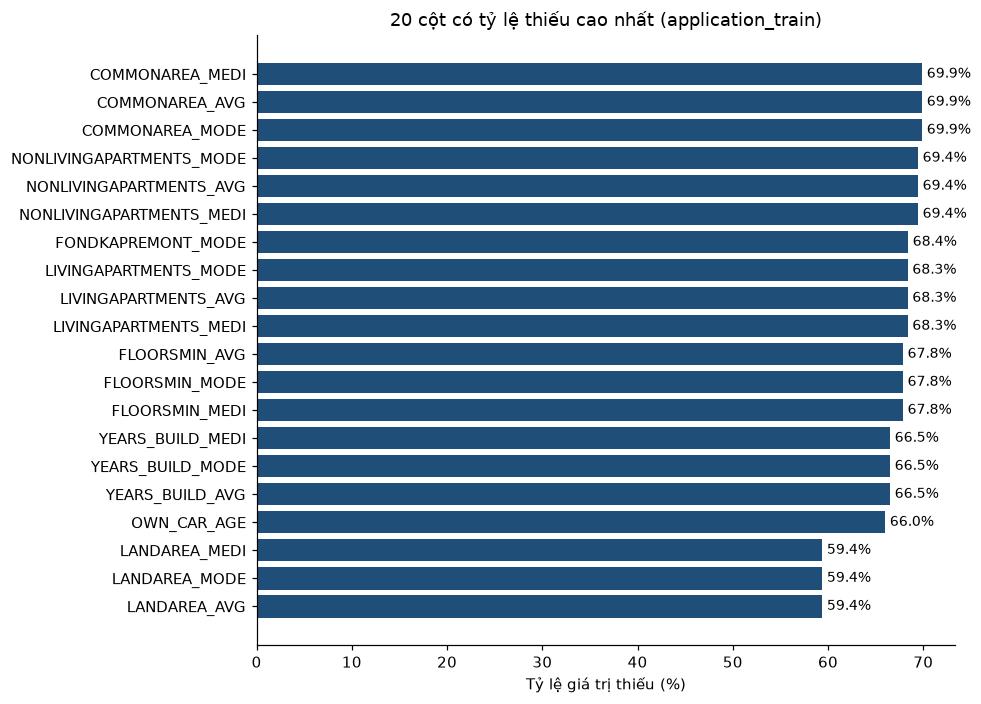

,cot,ti_le_thieu_%
76,COMMONAREA_MEDI,69.87
48,COMMONAREA_AVG,69.87
62,COMMONAREA_MODE,69.87
70,NONLIVINGAPARTMENTS_MODE,69.43
56,NONLIVINGAPARTMENTS_AVG,69.43
84,NONLIVINGAPARTMENTS_MEDI,69.43
86,FONDKAPREMONT_MODE,68.39
68,LIVINGAPARTMENTS_MODE,68.35
54,LIVINGAPARTMENTS_AVG,68.35
82,LIVINGAPARTMENTS_MEDI,68.35


In [8]:
# 2.2 Giá trị thiếu ở bảng hồ sơ: một lần quét Spark tính tỷ lệ null của mọi cột
n_app = app.count()
null_row = app.select([F.avg(F.col(c).isNull().cast("int")).alias(c) for c in app.columns]).first().asDict()
miss_pdf = (pd.DataFrame({"cot": list(null_row), "ti_le_thieu_%": [round(100 * v, 2) for v in null_row.values()]})
              .sort_values("ti_le_thieu_%", ascending=False))
print("Số cột có giá trị thiếu:", int((miss_pdf["ti_le_thieu_%"] > 0).sum()), "/", len(miss_pdf))
print("Số cột thiếu trên 50%:", int((miss_pdf["ti_le_thieu_%"] > 50).sum()))
miss_pdf.to_csv(RESULT_DIR / "bang_chat_luong_gia_tri_thieu.csv", index=False)

top = miss_pdf.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.cot, top["ti_le_thieu_%"], color=COLOR)
for i, v in enumerate(top["ti_le_thieu_%"]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Tỷ lệ giá trị thiếu (%)"); ax.set_title("20 cột có tỷ lệ thiếu cao nhất (application_train)")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_0_gia_tri_thieu.png", dpi=150); plt.show()
miss_pdf.head(10)

In [9]:
# 2.3 Ngoại lệ: phân vị của các cột tiền tệ và DAYS_EMPLOYED
OUT_COLS = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "DAYS_EMPLOYED"]
qs = [0.01, 0.5, 0.99, 0.999]
out_rows = []
for c in OUT_COLS:
    q = app.approxQuantile(c, qs, 0.001)
    mx = app.agg(F.max(c)).first()[0]
    out_rows.append({"cot": c, "p1": q[0], "trung_vi": q[1], "p99": q[2], "p99.9": q[3], "max": mx})
out_pdf = pd.DataFrame(out_rows)
n_anom = app.filter(F.col("DAYS_EMPLOYED") == 365243).count()
print(f"DAYS_EMPLOYED = 365243 (mã đặc biệt): {n_anom:,} hồ sơ ({100 * n_anom / n_app:.1f}%)")
out_pdf.to_csv(RESULT_DIR / "bang_chat_luong_ngoai_le.csv", index=False)

# Giới hạn thu nhập ở phân vị 99,9% (winsorize) để vài giá trị cực lớn không làm lệch các tỷ lệ
INCOME_CAP = float(out_pdf.set_index("cot").loc["AMT_INCOME_TOTAL", "p99.9"])
app = app.withColumn("AMT_INCOME_TOTAL", F.least(F.col("AMT_INCOME_TOTAL"), F.lit(INCOME_CAP)))
print("Ngưỡng giới hạn thu nhập:", f"{INCOME_CAP:,.0f}")
out_pdf

DAYS_EMPLOYED = 365243 (mã đặc biệt): 55,374 hồ sơ (18.0%)
Ngưỡng giới hạn thu nhập: 117,000,000


,cot,p1,trung_vi,p99,p99.9,max
0,AMT_INCOME_TOTAL,45000.0,148500.0,450000.0,117000000.0,117000000.0
1,AMT_CREDIT,76410.0,513531.0,1824480.0,4050000.0,4050000.0
2,AMT_ANNUITY,6183.0,24907.5,69903.0,258025.5,258025.5
3,DAYS_EMPLOYED,-10813.0,-1216.0,365243.0,365243.0,365243.0


## 3. Khám phá dữ liệu bằng Spark SQL

26/11/19 16:05:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:05:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:05:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:05:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:05:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:05:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 1

,TARGET,so_ho_so,ti_le_phan_tram
0,0,282686,91.93
1,1,24825,8.07


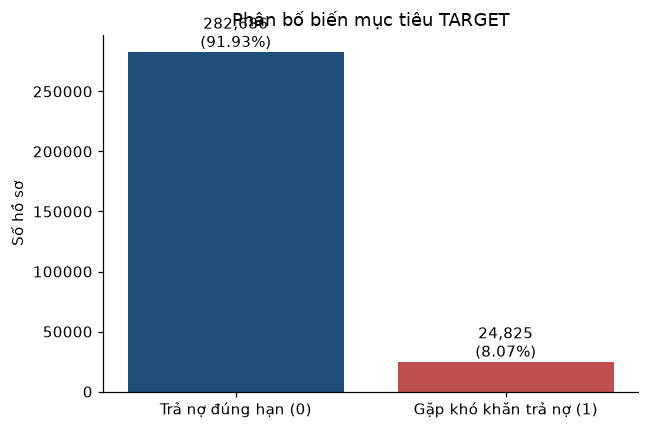

In [10]:
app.createOrReplaceTempView("app")
target_pdf = spark.sql("""
    SELECT TARGET,
           COUNT(*) AS so_ho_so,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS ti_le_phan_tram
    FROM app GROUP BY TARGET ORDER BY TARGET
""").toPandas()
display(target_pdf)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Trả nợ đúng hạn (0)", "Gặp khó khăn trả nợ (1)"], target_pdf.so_ho_so, color=[COLOR, ACCENT])
for b, v, p in zip(bars, target_pdf.so_ho_so, target_pdf.ti_le_phan_tram):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({p}%)", ha="center", va="bottom")
ax.set_ylabel("Số hồ sơ"); ax.set_title("Phân bố biến mục tiêu TARGET")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_1_phan_bo_target.png", dpi=150); plt.show()
target_pdf.to_csv(DASH_DIR / "eda_target.csv", index=False)

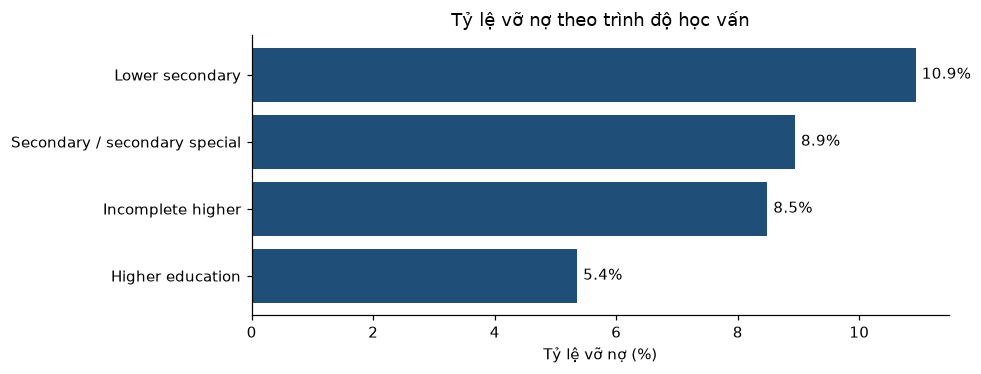

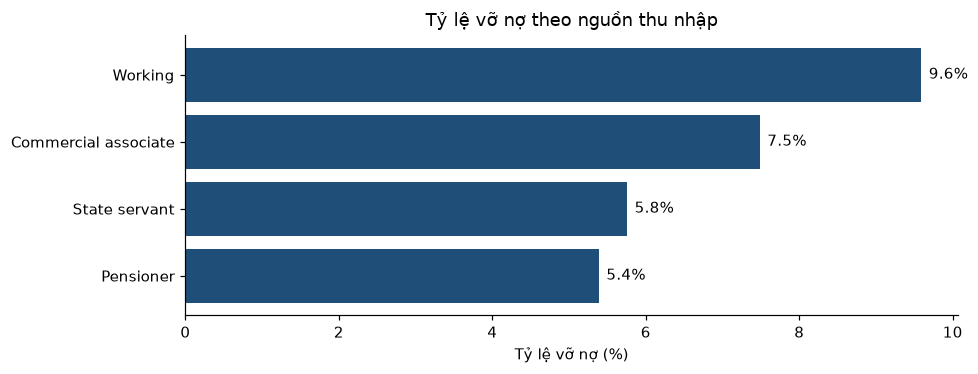

In [11]:
def rate_by(df, col, title, fname, min_n=500):
    """Tỷ lệ vỡ nợ theo từng nhóm của một cột phân loại."""
    pdf = (df.groupBy(col)
             .agg(F.count("*").alias("so_ho_so"), F.avg("TARGET").alias("ti_le_vo_no"))
             .filter(F.col("so_ho_so") >= min_n)
             .orderBy("ti_le_vo_no").toPandas())
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(pdf) + 1.5))
    vals = pdf.ti_le_vo_no * 100
    ax.barh(pdf[col].astype(str), vals, color=COLOR)
    for i, v in enumerate(vals):
        ax.text(v + 0.1, i, f"{v:.1f}%", va="center")
    ax.set_xlabel("Tỷ lệ vỡ nợ (%)"); ax.set_title(title)
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()
    return pdf

edu_pdf = rate_by(app, "NAME_EDUCATION_TYPE", "Tỷ lệ vỡ nợ theo trình độ học vấn", "hinh_4_2_theo_hoc_van.png")
inc_pdf = rate_by(app, "NAME_INCOME_TYPE", "Tỷ lệ vỡ nợ theo nguồn thu nhập", "hinh_4_3_theo_thu_nhap.png")
edu_pdf.to_csv(DASH_DIR / "eda_hoc_van.csv", index=False)
inc_pdf.to_csv(DASH_DIR / "eda_thu_nhap.csv", index=False)

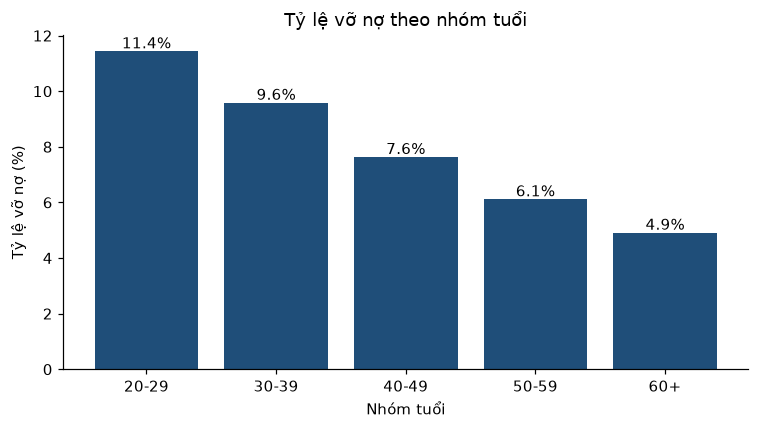

,nhom_tuoi,so_ho_so,ti_le_vo_no
0,20-29,45186,0.114438
1,30-39,82331,0.095918
2,40-49,76599,0.076411
3,50-59,68094,0.061210
4,60+,35301,0.049177


In [12]:
age_df = (app.withColumn("tuoi", F.floor(-F.col("DAYS_BIRTH") / 365.25))
             .withColumn("nhom_tuoi",
                         F.when(F.col("tuoi") < 30, "20-29").when(F.col("tuoi") < 40, "30-39")
                          .when(F.col("tuoi") < 50, "40-49").when(F.col("tuoi") < 60, "50-59")
                          .otherwise("60+")))
age_pdf = (age_df.groupBy("nhom_tuoi").agg(F.count("*").alias("so_ho_so"), F.avg("TARGET").alias("ti_le_vo_no"))
                 .orderBy("nhom_tuoi").toPandas())
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(age_pdf.nhom_tuoi, age_pdf.ti_le_vo_no * 100, color=COLOR)
for i, v in enumerate(age_pdf.ti_le_vo_no * 100):
    ax.text(i, v + 0.1, f"{v:.1f}%", ha="center")
ax.set_xlabel("Nhóm tuổi"); ax.set_ylabel("Tỷ lệ vỡ nợ (%)"); ax.set_title("Tỷ lệ vỡ nợ theo nhóm tuổi")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_4_theo_tuoi.png", dpi=150); plt.show()

age_pdf.to_csv(DASH_DIR / "eda_tuoi.csv", index=False)
age_pdf

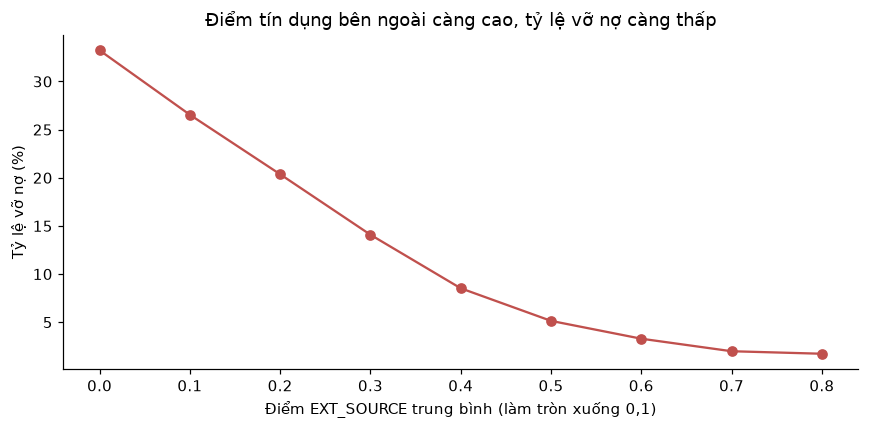

In [13]:
# Điểm tín dụng bên ngoài (EXT_SOURCE) — chia 10 nhóm bằng nhau theo giá trị trung bình
ext_df = (app.withColumn("EXT_MEAN", F.expr("""
                aggregate(filter(array(EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3), x -> x IS NOT NULL), 0D, (acc, x) -> acc + x)
                / size(filter(array(EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3), x -> x IS NOT NULL))"""))
             .filter(F.col("EXT_MEAN").isNotNull())
             .withColumn("nhom", F.floor(F.col("EXT_MEAN") * 10).cast("int")))
ext_pdf = (ext_df.groupBy("nhom").agg(F.count("*").alias("so_ho_so"), F.avg("TARGET").alias("ti_le_vo_no"))
                 .orderBy("nhom").toPandas())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ext_pdf.nhom / 10, ext_pdf.ti_le_vo_no * 100, marker="o", color=ACCENT)
ax.set_xlabel("Điểm EXT_SOURCE trung bình (làm tròn xuống 0,1)"); ax.set_ylabel("Tỷ lệ vỡ nợ (%)")
ax.set_title("Điểm tín dụng bên ngoài càng cao, tỷ lệ vỡ nợ càng thấp")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_5_theo_ext_source.png", dpi=150); plt.show()
ext_pdf.to_csv(DASH_DIR / "eda_ext_source.csv", index=False)

## 4. Làm sạch và tạo đặc trưng trên bảng hồ sơ

In [14]:
app_fe = (app
    # DAYS_EMPLOYED = 365243 là giá trị mã hóa sai (≈ 1000 năm) → đánh dấu rồi đặt null
    .withColumn("DAYS_EMPLOYED_ANOM", (F.col("DAYS_EMPLOYED") == 365243).cast("int"))
    .withColumn("DAYS_EMPLOYED", F.when(F.col("DAYS_EMPLOYED") == 365243, None).otherwise(F.col("DAYS_EMPLOYED")))
    .withColumn("AGE_YEARS", -F.col("DAYS_BIRTH") / 365.25)
    .withColumn("CREDIT_INCOME_RATIO",  F.col("AMT_CREDIT")  / F.col("AMT_INCOME_TOTAL"))
    .withColumn("ANNUITY_INCOME_RATIO", F.col("AMT_ANNUITY") / F.col("AMT_INCOME_TOTAL"))
    .withColumn("CREDIT_TERM",          F.col("AMT_ANNUITY") / F.col("AMT_CREDIT"))
    .withColumn("GOODS_CREDIT_RATIO",   F.col("AMT_GOODS_PRICE") / F.col("AMT_CREDIT"))
    .withColumn("EMPLOYED_AGE_RATIO",   F.col("DAYS_EMPLOYED") / F.col("DAYS_BIRTH"))
    .withColumn("EXT_SOURCE_MEAN", F.expr("""
        aggregate(filter(array(EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3), x -> x IS NOT NULL), 0D, (acc, x) -> acc + x)
        / size(filter(array(EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3), x -> x IS NOT NULL))"""))
    .withColumn("EXT_SOURCE_PROD", F.col("EXT_SOURCE_1") * F.col("EXT_SOURCE_2") * F.col("EXT_SOURCE_3")))
print("Số cột bảng hồ sơ sau khi tạo đặc trưng:", len(app_fe.columns))

Số cột bảng hồ sơ sau khi tạo đặc trưng: 131


## 5. Tổng hợp đặc trưng từ 6 bảng lịch sử

In [15]:
# 4.1 bureau_balance (27 triệu dòng) → theo từng khoản vay ở tổ chức khác
bb_agg = (dfs["bureau_balance"].groupBy("SK_ID_BUREAU").agg(
    F.count("*").alias("BB_MONTHS"),
    F.avg(F.col("STATUS").isin("1", "2", "3", "4", "5").cast("int")).alias("BB_LATE_RATIO")))

# 4.2 bureau → theo từng khách hàng
bureau_agg = (dfs["bureau"].join(bb_agg, "SK_ID_BUREAU", "left").groupBy("SK_ID_CURR").agg(
    F.count("*").alias("BUR_COUNT"),
    F.sum((F.col("CREDIT_ACTIVE") == "Active").cast("int")).alias("BUR_ACTIVE_COUNT"),
    F.sum("AMT_CREDIT_SUM").alias("BUR_CREDIT_SUM"),
    F.sum("AMT_CREDIT_SUM_DEBT").alias("BUR_DEBT_SUM"),
    F.sum("AMT_CREDIT_SUM_OVERDUE").alias("BUR_OVERDUE_SUM"),
    F.max("CREDIT_DAY_OVERDUE").alias("BUR_MAX_DAY_OVERDUE"),
    F.avg("DAYS_CREDIT").alias("BUR_DAYS_CREDIT_MEAN"),
    F.sum("CNT_CREDIT_PROLONG").alias("BUR_PROLONG_SUM"),
    F.avg("BB_LATE_RATIO").alias("BUR_BB_LATE_RATIO_MEAN"))
  .withColumn("BUR_DEBT_CREDIT_RATIO", F.col("BUR_DEBT_SUM") / F.col("BUR_CREDIT_SUM")))

# 4.3 previous_application → lịch sử xin vay tại Home Credit
prev_agg = dfs["previous_application"].groupBy("SK_ID_CURR").agg(
    F.count("*").alias("PREV_COUNT"),
    F.avg((F.col("NAME_CONTRACT_STATUS") == "Approved").cast("int")).alias("PREV_APPROVED_RATIO"),
    F.avg((F.col("NAME_CONTRACT_STATUS") == "Refused").cast("int")).alias("PREV_REFUSED_RATIO"),
    F.avg("AMT_APPLICATION").alias("PREV_AMT_APPLICATION_MEAN"),
    F.avg("AMT_CREDIT").alias("PREV_AMT_CREDIT_MEAN"),
    F.avg(F.col("AMT_CREDIT") / F.col("AMT_APPLICATION")).alias("PREV_CREDIT_APP_RATIO_MEAN"),
    F.max("DAYS_DECISION").alias("PREV_LAST_DECISION_DAYS"))

# 4.4 installments_payments (13,6 triệu dòng) → hành vi trả góp
ins = (dfs["installments_payments"]
       .withColumn("DPD", F.greatest(F.col("DAYS_ENTRY_PAYMENT") - F.col("DAYS_INSTALMENT"), F.lit(0)))
       .withColumn("PAY_DIFF", F.col("AMT_INSTALMENT") - F.col("AMT_PAYMENT")))
ins_agg = ins.groupBy("SK_ID_CURR").agg(
    F.count("*").alias("INS_COUNT"),
    F.avg((F.col("DPD") > 0).cast("int")).alias("INS_LATE_RATIO"),
    F.max("DPD").alias("INS_DPD_MAX"),
    F.avg("DPD").alias("INS_DPD_MEAN"),
    F.avg((F.col("PAY_DIFF") > 0).cast("int")).alias("INS_UNDERPAID_RATIO"),
    F.sum("PAY_DIFF").alias("INS_PAY_DIFF_SUM"))

# 4.5 POS_CASH_balance (10 triệu dòng)
pos_agg = dfs["POS_CASH_balance"].groupBy("SK_ID_CURR").agg(
    F.count("*").alias("POS_MONTHS"),
    F.max("SK_DPD").alias("POS_DPD_MAX"),
    F.avg((F.col("SK_DPD") > 0).cast("int")).alias("POS_LATE_RATIO"))

# 4.6 credit_card_balance
cc_agg = dfs["credit_card_balance"].groupBy("SK_ID_CURR").agg(
    F.count("*").alias("CC_MONTHS"),
    F.avg("AMT_BALANCE").alias("CC_BALANCE_MEAN"),
    F.avg(F.col("AMT_BALANCE") / F.col("AMT_CREDIT_LIMIT_ACTUAL")).alias("CC_UTILIZATION_MEAN"),
    F.max("SK_DPD").alias("CC_DPD_MAX"))

In [16]:
COUNT_COLS = ["BUR_COUNT", "BUR_ACTIVE_COUNT", "PREV_COUNT", "INS_COUNT", "POS_MONTHS", "CC_MONTHS"]

with timer("4_tong_hop_join_ghi_parquet"):
    full = (app_fe
            .join(bureau_agg, "SK_ID_CURR", "left")
            .join(prev_agg,   "SK_ID_CURR", "left")
            .join(ins_agg,    "SK_ID_CURR", "left")
            .join(pos_agg,    "SK_ID_CURR", "left")
            .join(cc_agg,     "SK_ID_CURR", "left")
            .fillna(0, subset=COUNT_COLS))           # không có lịch sử → đếm = 0
    full.write.mode("overwrite").parquet(pq_path("features"))

full = spark.read.parquet(pq_path("features"))
N_ROWS, N_COLS = full.count(), len(full.columns)
print(f"Bảng đặc trưng cuối: {N_ROWS:,} hồ sơ × {N_COLS} cột")
# full.explain(mode="formatted")   # bỏ dấu # để xem kế hoạch thực thi của Spark

[4_tong_hop_join_ghi_parquet] 13.38 giây
Bảng đặc trưng cuối: 307,511 hồ sơ × 161 cột


## 6. Chuẩn bị dữ liệu cho Spark MLlib

In [17]:
CAT_COLS = [c for c, t in full.dtypes if t == "string"]
NUM_COLS = [c for c, t in full.dtypes if t != "string" and c not in ("SK_ID_CURR", "TARGET")]
print(f"{len(NUM_COLS)} cột số, {len(CAT_COLS)} cột phân loại")

full = full.select("SK_ID_CURR", F.col("TARGET").cast("double").alias("TARGET"),
                   *[F.col(c).cast("double").alias(c) for c in NUM_COLS], *CAT_COLS)

# Dữ liệu mất cân bằng (~8% vỡ nợ) → gán trọng số cân bằng cho từng lớp
POS_RATIO = full.filter("TARGET = 1").count() / N_ROWS
full = full.withColumn("weight", F.when(F.col("TARGET") == 1, 0.5 / POS_RATIO).otherwise(0.5 / (1 - POS_RATIO)))
print(f"Tỷ lệ vỡ nợ: {POS_RATIO:.2%}")

train, test = full.randomSplit([0.8, 0.2], seed=SEED)
train, test = train.cache(), test.cache()
print(f"Train: {train.count():,} | Test: {test.count():,}")

143 cột số, 16 cột phân loại
Tỷ lệ vỡ nợ: 8.07%


Train: 246,215 | Test: 61,296


In [18]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, Imputer, VectorAssembler, StandardScaler

prep = Pipeline(stages=[
    StringIndexer(inputCols=CAT_COLS, outputCols=[c + "_idx" for c in CAT_COLS], handleInvalid="keep"),
    OneHotEncoder(inputCols=[c + "_idx" for c in CAT_COLS], outputCols=[c + "_ohe" for c in CAT_COLS],
                  handleInvalid="keep"),
    Imputer(inputCols=NUM_COLS, outputCols=[c + "_imp" for c in NUM_COLS], strategy="median"),
    VectorAssembler(inputCols=[c + "_imp" for c in NUM_COLS] + [c + "_ohe" for c in CAT_COLS],
                    outputCol="features_raw", handleInvalid="keep"),
    StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True),
])

with timer("5_fit_tien_xu_ly"):
    prep_model = prep.fit(train)
    train_t = prep_model.transform(train).select("SK_ID_CURR", "TARGET", "weight", "features", "features_raw").cache()
    test_t  = prep_model.transform(test).select("SK_ID_CURR", "TARGET", "weight", "features", "features_raw").cache()
    train_t.count(); test_t.count()

attrs = train_t.schema["features_raw"].metadata["ml_attr"]["attrs"]
FEATURE_NAMES = [n for _, n in sorted((a["idx"], a["name"]) for grp in attrs.values() for a in grp)]
print("Số chiều vector đặc trưng:", len(FEATURE_NAMES))

[5_fit_tien_xu_ly] 8.46 giây
Số chiều vector đặc trưng: 299


## 7. Huấn luyện và đánh giá 3 mô hình

Logistic Regression là **mô hình baseline** (mốc so sánh). Random Forest và GBT là hai hướng cải thiện: học được quan hệ phi tuyến giữa các đặc trưng.

In [19]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

common = dict(featuresCol="features", labelCol="TARGET", weightCol="weight")
MODELS = {
    "Logistic Regression": LogisticRegression(maxIter=100, regParam=0.01, elasticNetParam=0.0, **common),
    "Random Forest":       RandomForestClassifier(numTrees=100, maxDepth=8, seed=SEED, **common),
    "GBT":                 GBTClassifier(maxIter=60, maxDepth=5, stepSize=0.1, seed=SEED, **common),
}
roc_eval = BinaryClassificationEvaluator(labelCol="TARGET", metricName="areaUnderROC")
pr_eval  = BinaryClassificationEvaluator(labelCol="TARGET", metricName="areaUnderPR")

def threshold_metrics(pred, thr=0.5):
    c = (pred.select("TARGET", (vector_to_array("probability")[1] >= thr).cast("double").alias("yhat"))
             .groupBy("TARGET", "yhat").count().toPandas())
    get = lambda y, p: int(c[(c.TARGET == y) & (c.yhat == p)]["count"].sum())
    tp, fp, fn, tn = get(1, 1), get(0, 1), get(1, 0), get(0, 0)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall    = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, Accuracy=(tp + tn) / (tp + fp + fn + tn),
                Precision=precision, Recall=recall, F1=f1)

fitted, preds, metrics = {}, {}, []
for name, est in MODELS.items():
    with timer(f"6_train_{name}"):
        fitted[name] = est.fit(train_t)
    preds[name] = fitted[name].transform(test_t).cache()
    m = {"Mo_hinh": name, "AUC_ROC": roc_eval.evaluate(preds[name]), "AUC_PR": pr_eval.evaluate(preds[name]),
         **threshold_metrics(preds[name]), "Thoi_gian_huan_luyen_s": TIMINGS[f"6_train_{name}"]}
    metrics.append(m)
    print(f"{name:20s} AUC-ROC={m['AUC_ROC']:.4f}  AUC-PR={m['AUC_PR']:.4f}  Recall={m['Recall']:.3f}  F1={m['F1']:.3f}")

metrics_pdf = pd.DataFrame(metrics).round(4)
metrics_pdf.to_csv(RESULT_DIR / "bang_4_3_ket_qua_mo_hinh.csv", index=False)
metrics_pdf

26/11/19 16:05:49 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/19 16:05:49 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


[6_train_Logistic Regression] 3.66 giây
Logistic Regression  AUC-ROC=0.7621  AUC-PR=0.2385  Recall=0.695  F1=0.266


26/11/19 16:06:00 WARN DAGScheduler: Broadcasting large task binary with size 1411.0 KiB
26/11/19 16:06:04 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB
26/11/19 16:06:09 WARN DAGScheduler: Broadcasting large task binary with size 4.3 MiB
                                                                                

[6_train_Random Forest] 21.55 giây


26/11/19 16:06:14 WARN DAGScheduler: Broadcasting large task binary with size 3.0 MiB
26/11/19 16:06:15 WARN DAGScheduler: Broadcasting large task binary with size 3.1 MiB
26/11/19 16:06:15 WARN DAGScheduler: Broadcasting large task binary with size 3.1 MiB
26/11/19 16:06:15 WARN DAGScheduler: Broadcasting large task binary with size 3.1 MiB
26/11/19 16:06:16 WARN DAGScheduler: Broadcasting large task binary with size 3.1 MiB


Random Forest        AUC-ROC=0.7488  AUC-PR=0.2186  Recall=0.675  F1=0.264
[6_train_GBT] 21.41 giây
GBT                  AUC-ROC=0.7645  AUC-PR=0.2463  Recall=0.679  F1=0.273


,Mo_hinh,AUC_ROC,AUC_PR,TP,FP,FN,TN,Accuracy,Precision,Recall,F1,Thoi_gian_huan_luyen_s
0,Logistic Regression,0.7621,0.2385,3356,17005,1473,39462,0.6985,0.1648,0.6950,0.2665,3.66
1,Random Forest,0.7488,0.2186,3261,16637,1568,39830,0.7030,0.1639,0.6753,0.2638,21.55
2,GBT,0.7645,0.2463,3278,15946,1551,40521,0.7145,0.1705,0.6788,0.2726,21.41


26/11/19 16:06:39 WARN DAGScheduler: Broadcasting large task binary with size 3.1 MiB


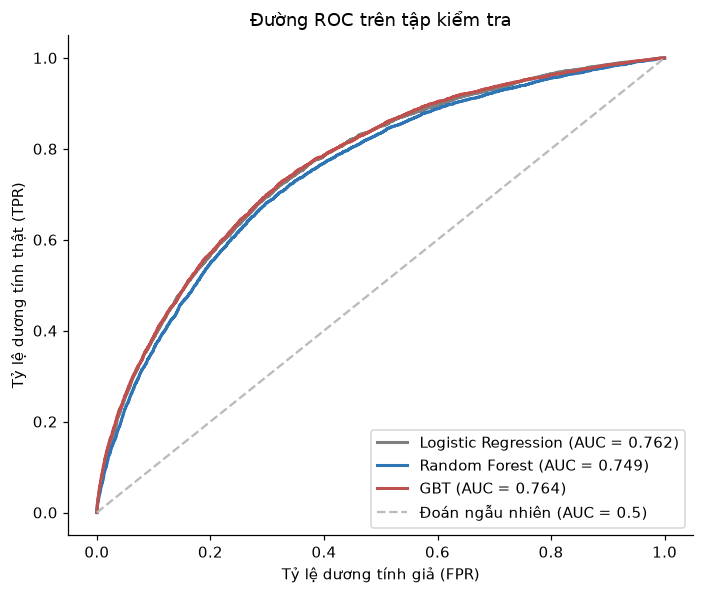

In [20]:
# Đường ROC của 3 mô hình (tập test nhỏ nên chuyển sang pandas để vẽ)
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (name, pred), color in zip(preds.items(), ["#7F7F7F", "#2E75B6", ACCENT]):
    pdf = pred.select("TARGET", vector_to_array("probability")[1].alias("p")).toPandas()
    fpr, tpr, _ = roc_curve(pdf.TARGET, pdf.p)
    auc = metrics_pdf.set_index("Mo_hinh").loc[name, "AUC_ROC"]
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", color=color, lw=2)
ax.plot([0, 1], [0, 1], "--", color="#BBBBBB", label="Đoán ngẫu nhiên (AUC = 0.5)")
ax.set_xlabel("Tỷ lệ dương tính giả (FPR)"); ax.set_ylabel("Tỷ lệ dương tính thật (TPR)")
ax.set_title("Đường ROC trên tập kiểm tra"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_6_duong_roc.png", dpi=150); plt.show()

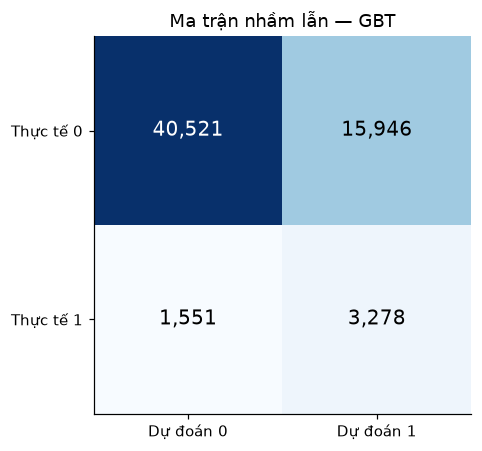

Mô hình tốt nhất theo AUC-ROC: GBT


In [21]:
# Ma trận nhầm lẫn của mô hình tốt nhất
BEST = metrics_pdf.sort_values("AUC_ROC", ascending=False).iloc[0]["Mo_hinh"]
row = metrics_pdf.set_index("Mo_hinh").loc[BEST]
cm = [[row.TN, row.FP], [row.FN, row.TP]]
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{int(cm[i][j]):,}", ha="center", va="center", fontsize=13,
                color="white" if cm[i][j] > max(map(max, cm)) / 2 else "black")
ax.set_xticks([0, 1], ["Dự đoán 0", "Dự đoán 1"]); ax.set_yticks([0, 1], ["Thực tế 0", "Thực tế 1"])
ax.set_title(f"Ma trận nhầm lẫn — {BEST}")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_7_ma_tran_nham_lan.png", dpi=150); plt.show()
print("Mô hình tốt nhất theo AUC-ROC:", BEST)

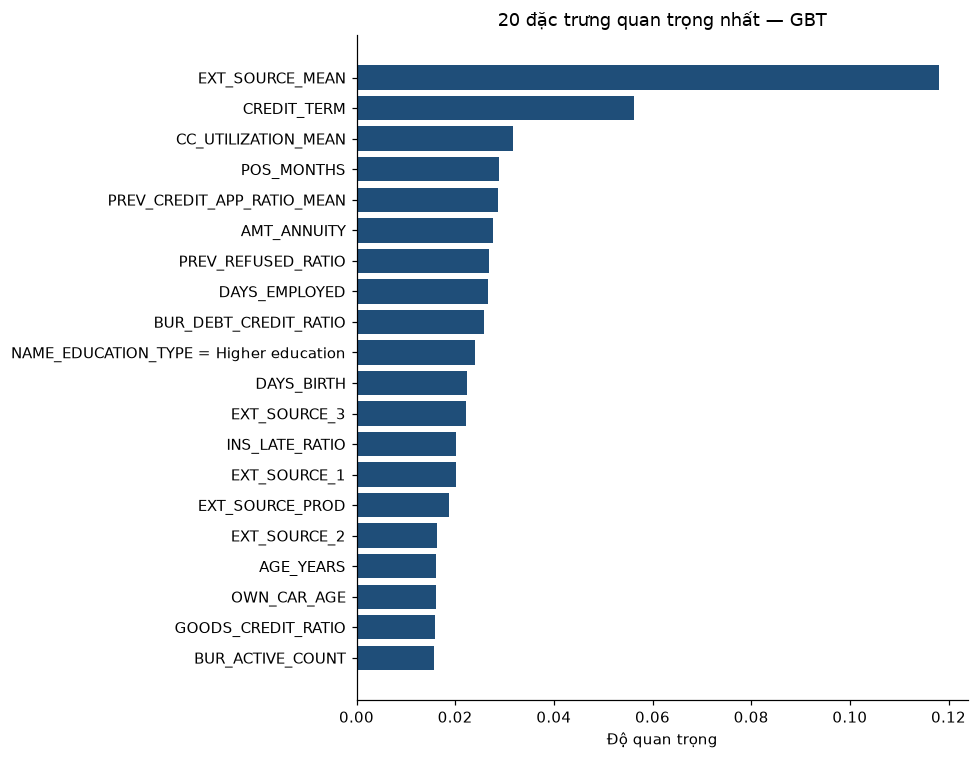

,dac_trung,do_quan_trong
111,EXT_SOURCE_MEAN,0.118043
108,CREDIT_TERM,0.056327
141,CC_UTILIZATION_MEAN,0.031819
136,POS_MONTHS,0.028953
128,PREV_CREDIT_APP_RATIO_MEAN,0.028661
3,AMT_ANNUITY,0.027635
125,PREV_REFUSED_RATIO,0.026816
7,DAYS_EMPLOYED,0.026644
122,BUR_DEBT_CREDIT_RATIO,0.025778
174,NAME_EDUCATION_TYPE = Higher education,0.023990


In [22]:
# Độ quan trọng đặc trưng của mô hình cây tốt nhất
tree_name = BEST if BEST != "Logistic Regression" else "GBT"
imp = fitted[tree_name].featureImportances.toArray()
clean = lambda n: n.replace("_imp", "").replace("_ohe_", " = ")
fi_pdf = (pd.DataFrame({"dac_trung": [clean(n) for n in FEATURE_NAMES], "do_quan_trong": imp})
            .sort_values("do_quan_trong", ascending=False).head(20))
fi_pdf.to_csv(RESULT_DIR / "bang_4_5_do_quan_trong_dac_trung.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(fi_pdf.dac_trung[::-1], fi_pdf.do_quan_trong[::-1], color=COLOR)
ax.set_xlabel("Độ quan trọng"); ax.set_title(f"20 đặc trưng quan trọng nhất — {tree_name}")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_8_do_quan_trong.png", dpi=150); plt.show()
fi_pdf

In [23]:
# (Tùy chọn) Tinh chỉnh siêu tham số GBT bằng CrossValidator 3-fold trên 30% tập train
if RUN_TUNING:
    from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
    gbt = GBTClassifier(seed=SEED, **common)
    grid = (ParamGridBuilder().addGrid(gbt.maxDepth, [4, 6]).addGrid(gbt.maxIter, [40, 80]).build())
    cv = CrossValidator(estimator=gbt, estimatorParamMaps=grid, evaluator=roc_eval, numFolds=3,
                        parallelism=2, seed=SEED)
    with timer("7_cross_validation"):
        cv_model = cv.fit(train_t.sample(fraction=0.3, seed=SEED))
    for params, score in zip(grid, cv_model.avgMetrics):
        print({p.name: v for p, v in params.items()}, round(score, 4))

## 8. So sánh thời gian: pandas và Spark

[8a_pandas_csv] 1.64 giây


[8b_spark_csv] 4.95 giây
[8c_spark_parquet] 0.43 giây


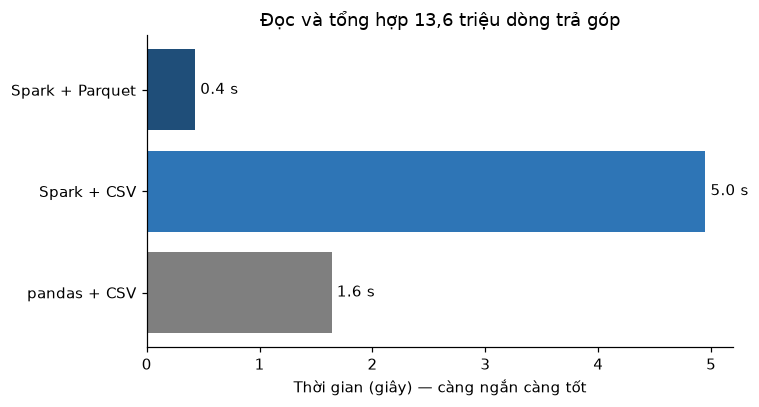

,Cach_xu_ly,Thoi_gian_s
0,pandas + CSV,1.64
1,Spark + CSV,4.95
2,Spark + Parquet,0.43


In [24]:
# pandas chỉ đọc được tệp trên máy (data/), Spark đọc từ nơi lưu trữ đã chọn (HDFS hoặc cục bộ)
# Cùng một tác vụ: đọc installments_payments (13,6 triệu dòng) + tính DPD + tổng hợp theo khách hàng
with timer("8a_pandas_csv"):
    ip = pd.read_csv(DATA_DIR / "installments_payments.csv")
    ip["DPD"] = (ip.DAYS_ENTRY_PAYMENT - ip.DAYS_INSTALMENT).clip(lower=0)
    _ = ip.groupby("SK_ID_CURR").agg(n=("DPD", "size"), dpd_max=("DPD", "max"), dpd_mean=("DPD", "mean"))
    del ip

def spark_task(df):
    return (df.withColumn("DPD", F.greatest(F.col("DAYS_ENTRY_PAYMENT") - F.col("DAYS_INSTALMENT"), F.lit(0)))
              .groupBy("SK_ID_CURR").agg(F.count("*").alias("n"), F.max("DPD").alias("dpd_max"),
                                         F.avg("DPD").alias("dpd_mean"))
              .count())

with timer("8b_spark_csv"):
    spark_task(spark.read.csv(raw_path("installments_payments"), header=True, inferSchema=True))
with timer("8c_spark_parquet"):
    spark_task(spark.read.parquet(pq_path("installments_payments")))

cmp = pd.DataFrame({"Cach_xu_ly": ["pandas + CSV", "Spark + CSV", "Spark + Parquet"],
                    "Thoi_gian_s": [TIMINGS["8a_pandas_csv"], TIMINGS["8b_spark_csv"], TIMINGS["8c_spark_parquet"]]})
cmp.to_csv(RESULT_DIR / "bang_4_4_so_sanh_thoi_gian.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(cmp.Cach_xu_ly, cmp.Thoi_gian_s, color=["#7F7F7F", "#2E75B6", COLOR])
for i, v in enumerate(cmp.Thoi_gian_s):
    ax.text(v, i, f" {v:.1f} s", va="center")
ax.set_xlabel("Thời gian (giây) — càng ngắn càng tốt"); ax.set_title("Đọc và tổng hợp 13,6 triệu dòng trả góp")
plt.tight_layout(); plt.savefig(FIG_DIR / "hinh_4_9_so_sanh_thoi_gian.png", dpi=150); plt.show()
cmp

## 9. Demo chấm điểm, lưu mô hình và xuất dữ liệu dashboard

In [25]:
def risk_level(p):
    return "Cao" if p >= 0.7 else ("Trung bình" if p >= 0.4 else "Thấp")

demo = (preds[BEST].select("SK_ID_CURR", "TARGET", vector_to_array("probability")[1].alias("xac_suat_vo_no"))
                   .orderBy(F.rand(SEED)).limit(8).toPandas())
demo["muc_rui_ro"] = demo.xac_suat_vo_no.apply(risk_level)
demo["xac_suat_vo_no"] = (demo.xac_suat_vo_no * 100).round(1).astype(str) + "%"
demo.rename(columns={"TARGET": "thuc_te"})

,SK_ID_CURR,thuc_te,xac_suat_vo_no,muc_rui_ro
0,104164,0.0,25.4%,Thấp
1,187253,0.0,11.8%,Thấp
2,277431,0.0,29.7%,Thấp
3,235949,0.0,63.1%,Trung bình
4,290687,1.0,77.7%,Cao
5,315924,0.0,41.3%,Trung bình
6,213772,1.0,83.4%,Cao
7,231468,0.0,12.4%,Thấp


In [26]:
# Lưu mô hình, pipeline tiền xử lý và toàn bộ số liệu cho báo cáo
prep_model.write().overwrite().save(str((RESULT_DIR / "prep_pipeline").resolve()))
BEST_DIR = RESULT_DIR / f"model_{BEST.replace(' ', '_')}"
fitted[BEST].write().overwrite().save(str(BEST_DIR.resolve()))

# Dữ liệu cho dashboard: xác suất dự đoán của 3 mô hình trên tập kiểm tra
pred_pdf = None
for name, pred in preds.items():
    p = pred.select("SK_ID_CURR", "TARGET", vector_to_array("probability")[1].alias(name)).toPandas()
    pred_pdf = p if pred_pdf is None else pred_pdf.merge(p[["SK_ID_CURR", name]], on="SK_ID_CURR")
pred_pdf.to_csv(DASH_DIR / "du_doan_tap_kiem_tra.csv", index=False)
miss_pdf.to_csv(DASH_DIR / "gia_tri_thieu.csv", index=False)

summary = {
    "so_ho_so": N_ROWS, "so_cot_bang_dac_trung": N_COLS, "so_chieu_vector": len(FEATURE_NAMES),
    "ti_le_vo_no": round(POS_RATIO, 4), "mo_hinh_tot_nhat": BEST,
    "luu_tru": STORAGE, "duong_dan_dac_trung": pq_path("features"),
    "duong_dan_mo_hinh": str(BEST_DIR.resolve()), "duong_dan_tien_xu_ly": str((RESULT_DIR / "prep_pipeline").resolve()),
    "thong_ke_du_lieu": stats_pdf.to_dict("records"),
    "chat_luong": {"dong_trung_lap": dup_pdf.to_dict("records"), "khoa_trung": int(dup_key),
                   "so_cot_thieu": int((miss_pdf["ti_le_thieu_%"] > 0).sum()),
                   "so_cot_thieu_tren_50": int((miss_pdf["ti_le_thieu_%"] > 50).sum()),
                   "days_employed_365243": int(n_anom), "nguong_thu_nhap": INCOME_CAP},
    "ket_qua_mo_hinh": metrics_pdf.to_dict("records"),
    "thoi_gian_s": TIMINGS, "spark_version": spark.version,
}
(RESULT_DIR / "ket_qua.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2,
                                                       default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print(json.dumps({k: summary[k] for k in ("so_ho_so", "ti_le_vo_no", "mo_hinh_tot_nhat")}, ensure_ascii=False))
print("Đã lưu hình vào", FIG_DIR, "và số liệu vào", RESULT_DIR)
print("Mở dashboard: streamlit run app.py")

26/11/19 16:06:48 WARN DAGScheduler: Broadcasting large task binary with size 3.1 MiB


{"so_ho_so": 307511, "ti_le_vo_no": 0.0807, "mo_hinh_tot_nhat": "GBT"}
Đã lưu hình vào results/figures và số liệu vào results
Mở dashboard: streamlit run app.py


In [27]:
# Dừng Spark khi xong (Spark UI ở localhost:4040 sẽ tắt theo)
# spark.stop()